**Image histogram**

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, data, img_as_ubyte
from skimage.exposure import equalize_hist, match_histograms

array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], dtype=uint8)
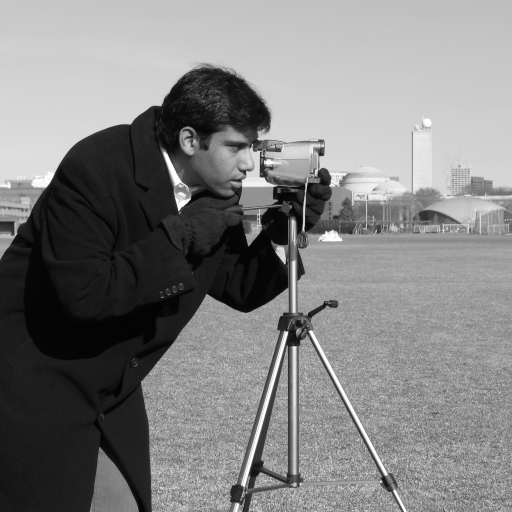

In [19]:
im = data.camera()
im

1 **Histogram**

[200 200 200 ... 151 152 149]


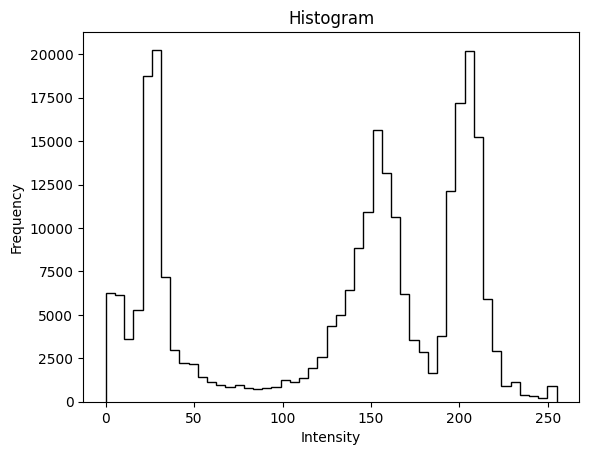

In [20]:
v = np.concatenate(im)
print(v)
bins = np.linspace(0, 255, 50)
plt.hist(v, bins, color='k', histtype='step')
plt.title("Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

array([[171, 159, 128, ..., 117, 108,  87],
       [171, 161, 158, ..., 122,  95,  86],
       [195, 168, 133, ..., 106, 114, 123],
       ...,
       [ 25,  29,  70, ...,  64,  92, 139],
       [ 34,  76,  97, ...,  69,  97, 140],
       [ 60, 105, 114, ...,  83, 112, 158]], dtype=uint8)
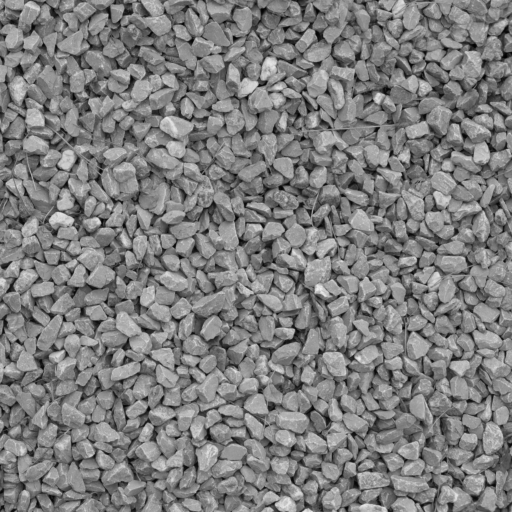

In [21]:
im_gravel = data.gravel()
im_gravel

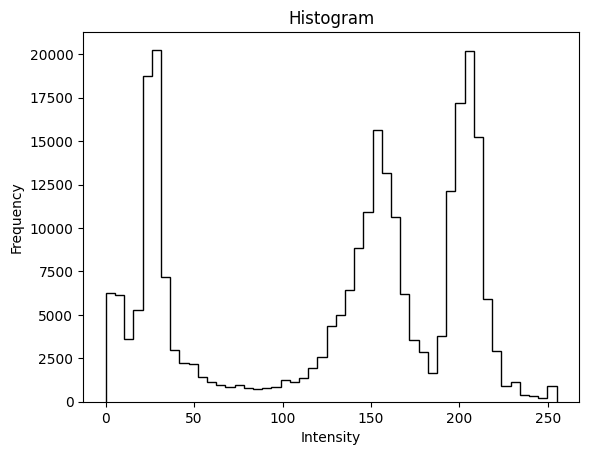

In [22]:
v = np.concatenate(im)
bins = np.linspace(0, 255, 50)
plt.hist(v, bins, color='k', histtype='step')
plt.title("Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

**2 Contrast Stretch**

array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], dtype=uint8)
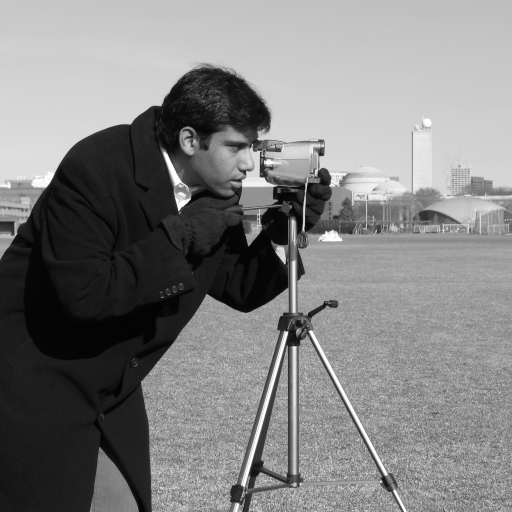

In [23]:
im_camera = data.camera()
im_camera

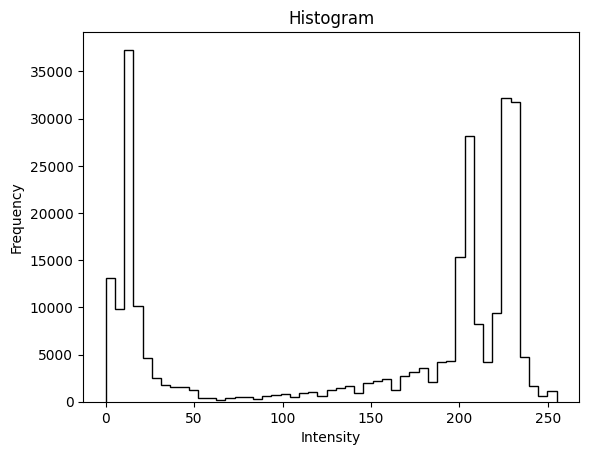

In [24]:
im_camera = data.camera()

r1 = 100 #min of OG image
r2 = 150 #max of OG image

s1 = 50 #min of final image
s2 = 200 #max of final image
imf = im.copy()


# Loop
for i in range(im.shape[0]): #row/height
 for j in range(im.shape[1]): #column/width
  v = im[i][j]
  if(0 <= v and v <= r1):
  #if(v >= 0 and v <= r1):
   imf[i][j] = (s1/r1 * v)
  elif(r1 < v and v <= r2):
   imf[i][j] = ((s2 - s1)/(r2 - r1)) * (v - r1) + s1
  elif(r2 < v and v <= 255):
   imf[i][j] = ((255 - s2)/(255 - r2)) * (v - r2) + s2

"""
for in range(im.shape[0]):
  for j in range(im.shape[0]):
    v = im[i][j]

    #pixels in dark range
    if(v >= 0 and v<= r1):
      imf[i][j] = (s1/r1 * v)

    elif(r1 < v and v <= r2):
      imf[i][j] = ((s2 - s1)/(r2 - r1)) * (v - r1) + s1

    elif(r2 < v and v <= 255):
      imf[i][j] = ((255 - s2)/(255 - r2)) * (v - r2) + s2

"""

#Plotting
v = np.concatenate(imf)
bins = np.linspace(0, 255, 50)
plt.hist(v, bins, color='k', histtype='step')
plt.title("Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

**3 Histogram equalization**

In [25]:
import inspect
from skimage.exposure import equalize_hist

# source code of equalize_hist
print(inspect.getsource(equalize_hist))

def equalize_hist(image, nbins=256, mask=None):
    """Return image after histogram equalization.

    Parameters
    ----------
    image : array
        Image array.
    nbins : int, optional
        Number of bins for image histogram. Note: this argument is
        ignored for integer images, for which each integer is its own
        bin.
    mask : ndarray of bools or 0s and 1s, optional
        Array of same shape as `image`. Only points at which mask == True
        are used for the equalization, which is applied to the whole image.

    Returns
    -------
    out : float array
        Image array after histogram equalization.

    Notes
    -----
    This function is adapted from [1]_ with the author's permission.

    References
    ----------
    .. [1] http://www.janeriksolem.net/histogram-equalization-with-python-and.html
    .. [2] https://en.wikipedia.org/wiki/Histogram_equalization

    """
    if mask is not None:
        mask = np.array(mask, dtype=bool)
        cdf, b

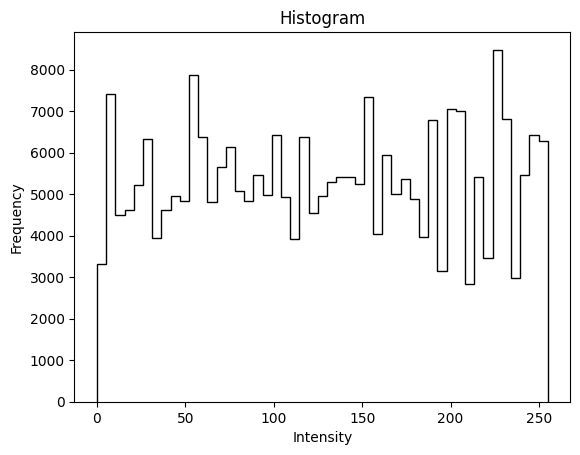

In [26]:
im = data.camera()

imeq = equalize_hist(im)
imeq = img_as_ubyte(imeq)

v = np.concatenate(imeq)
bins = np.linspace(0, 255, 50)

plt.hist(v, bins, color='k', histtype='step')
plt.title("Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

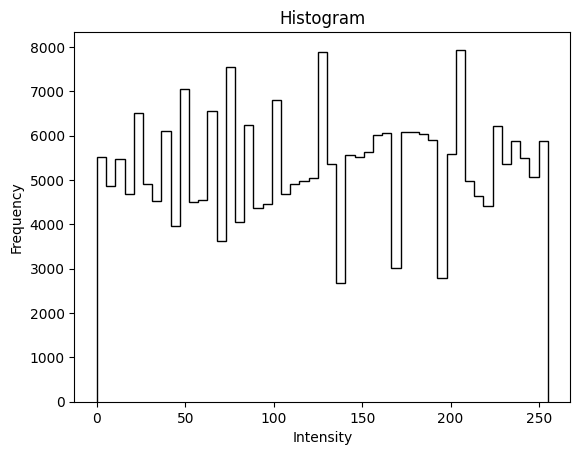

In [27]:
im = data.gravel()
imeq = equalize_hist(im)
imeq = img_as_ubyte(imeq)
v = np.concatenate(imeq)
bins = np.linspace(0, 255, 50)

plt.hist(v, bins, color='k', histtype='step')
plt.title("Histogram")
plt.xlabel('Intensity')
plt.ylabel('Frequency')
plt.show()

**4 Histogram matching**

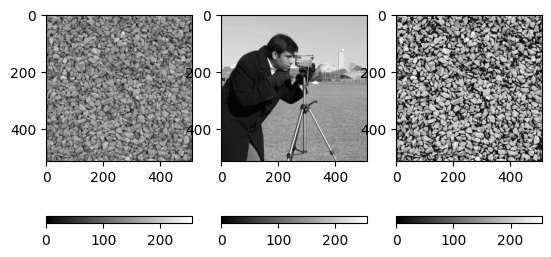

In [28]:
im = data.gravel()
imr = data.camera()
imm = match_histograms(im, imr)

fig = plt.figure()
ax = fig.add_subplot(1, 3, 1)
p = plt.imshow(im, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 2)
p = plt.imshow(imr, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

ax = fig.add_subplot(1, 3, 3)
p = plt.imshow(imm, cmap='gray')
c = plt.colorbar(orientation='horizontal')
plt.clim(0, 255)

In [29]:
import inspect
from skimage.exposure import equalize_hist

# Get and print the source code of equalize_hist
print(inspect.getsource(match_histograms))

@utils.channel_as_last_axis(channel_arg_positions=(0, 1))
def match_histograms(image, reference, *, channel_axis=None):
    """Adjust an image so that its cumulative histogram matches that of another.

    The adjustment is applied separately for each channel.

    Parameters
    ----------
    image : ndarray
        Input image. Can be gray-scale or in color.
    reference : ndarray
        Image to match histogram of. Must have the same number of channels as
        image.
    channel_axis : int or None, optional
        If None, the image is assumed to be a grayscale (single channel) image.
        Otherwise, this parameter indicates which axis of the array corresponds
        to channels.

    Returns
    -------
    matched : ndarray
        Transformed input image.

    Raises
    ------
    ValueError
        Thrown when the number of channels in the input image and the reference
        differ.

    References
    ----------
    .. [1] http://paulbourke.net/miscellaneous/equal